In [2]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
MODEL_PATH = PROJECT_ROOT / "models" / "tuned_xgboost.pkl"
PREPROCESSOR_PATH = PROJECT_ROOT / "models" / "preprocessor.pkl"
DATA_PATH = PROJECT_ROOT / "Dataset" / "churn_data.csv"

# Use 0.30 only if it was selected using validation data.
DECISION_THRESHOLD = 0.30
TEST_SIZE = 0.20

for path in [MODEL_PATH, PREPROCESSOR_PATH, DATA_PATH]:
    print(f"{path} | exists={path.exists()}")

c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\tuned_xgboost.pkl | exists=True
c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\models\preprocessor.pkl | exists=True
c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\Dataset\churn_data.csv | exists=True


In [3]:
for path in [MODEL_PATH, PREPROCESSOR_PATH, DATA_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}. Update the path in the configuration cell.")

model = joblib.load(MODEL_PATH)
preprocessor = joblib.load(PREPROCESSOR_PATH)
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Model:", type(model).__name__)
print("Preprocessor:", type(preprocessor).__name__)
display(df.head())

Dataset shape: (7032, 21)
Model: XGBClassifier
Preprocessor: ColumnTransformer


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,1 - 12
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,25 - 36
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1 - 12
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37 - 48
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1 - 12


In [4]:
target_candidates = ["Churn"]
target_col = next((c for c in target_candidates if c in df.columns), None)
if target_col is None:
    raise ValueError(f"Target column not found. Available columns: {df.columns.tolist()}")

target = df[target_col]
if target.dtype == object or str(target.dtype).startswith("category"):
    target_text = target.astype(str).str.strip().str.lower()
    target_map = {"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0, "churn": 1, "not churn": 0}
    y = target_text.map(target_map)
    if y.isna().any():
        raise ValueError(f"Unexpected target values: {target_text[y.isna()].unique().tolist()}")
    y = y.astype(int)
else:
    y = pd.to_numeric(target, errors="raise").astype(int)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"Expected binary target 0/1, found {sorted(y.unique())}")

if not hasattr(preprocessor, "feature_names_in_"):
    raise ValueError("Preprocessor has no feature_names_in_. Set feature_columns manually to match training.")

feature_columns = list(preprocessor.feature_names_in_)
missing = [c for c in feature_columns if c not in df.columns]
if missing:
    raise ValueError(f"Dataset missing required raw features: {missing}. Check the training schema, including tenure_group.")

X_raw = df.loc[:, feature_columns].copy()
print("Features used:", feature_columns)
display(y.value_counts().rename(index={0: "No churn", 1: "Churn"}).to_frame("row_count"))

Features used: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_group']


,row_count
Churn,
No churn,5163
Churn,1869


In [5]:
# FALLBACK split. For exact reproduction, load the original X_test/y_test or saved split indices.
_, X_test_raw, _, y_test = train_test_split(
    X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

X_test_t = preprocessor.transform(X_test_raw)
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()
else:
    X_test_t = np.asarray(X_test_t)

if X_test_t.ndim != 2 or not np.issubdtype(X_test_t.dtype, np.number):
    raise TypeError(f"Expected 2D numeric preprocessor output; shape={X_test_t.shape}, dtype={X_test_t.dtype}")

expected_n = getattr(model, "n_features_in_", X_test_t.shape[1])
if X_test_t.shape[1] != expected_n:
    raise ValueError(f"Feature mismatch: transformed={X_test_t.shape[1]}, model expects={expected_n}")

classes = list(getattr(model, "classes_", [0, 1]))
positive_idx = next((i for i, c in enumerate(classes) if str(c).strip().lower() in {"1", "yes", "true", "churn"}), None)
if positive_idx is None:
    positive_idx = 1 if len(classes) > 1 else 0

y_prob = model.predict_proba(X_test_t)[:, positive_idx]
y_pred = (y_prob >= DECISION_THRESHOLD).astype(int)

print(f"Test rows: {len(y_test)} | threshold: {DECISION_THRESHOLD:.2f}")

Test rows: 1407 | threshold: 0.30


,Metric,Score
0,Accuracy,0.7377
1,Precision,0.5044
2,Recall,0.7647
3,F1-score,0.6079
4,ROC-AUC,0.8378
5,Average Precision,0.6485
6,Brier Score,0.1389


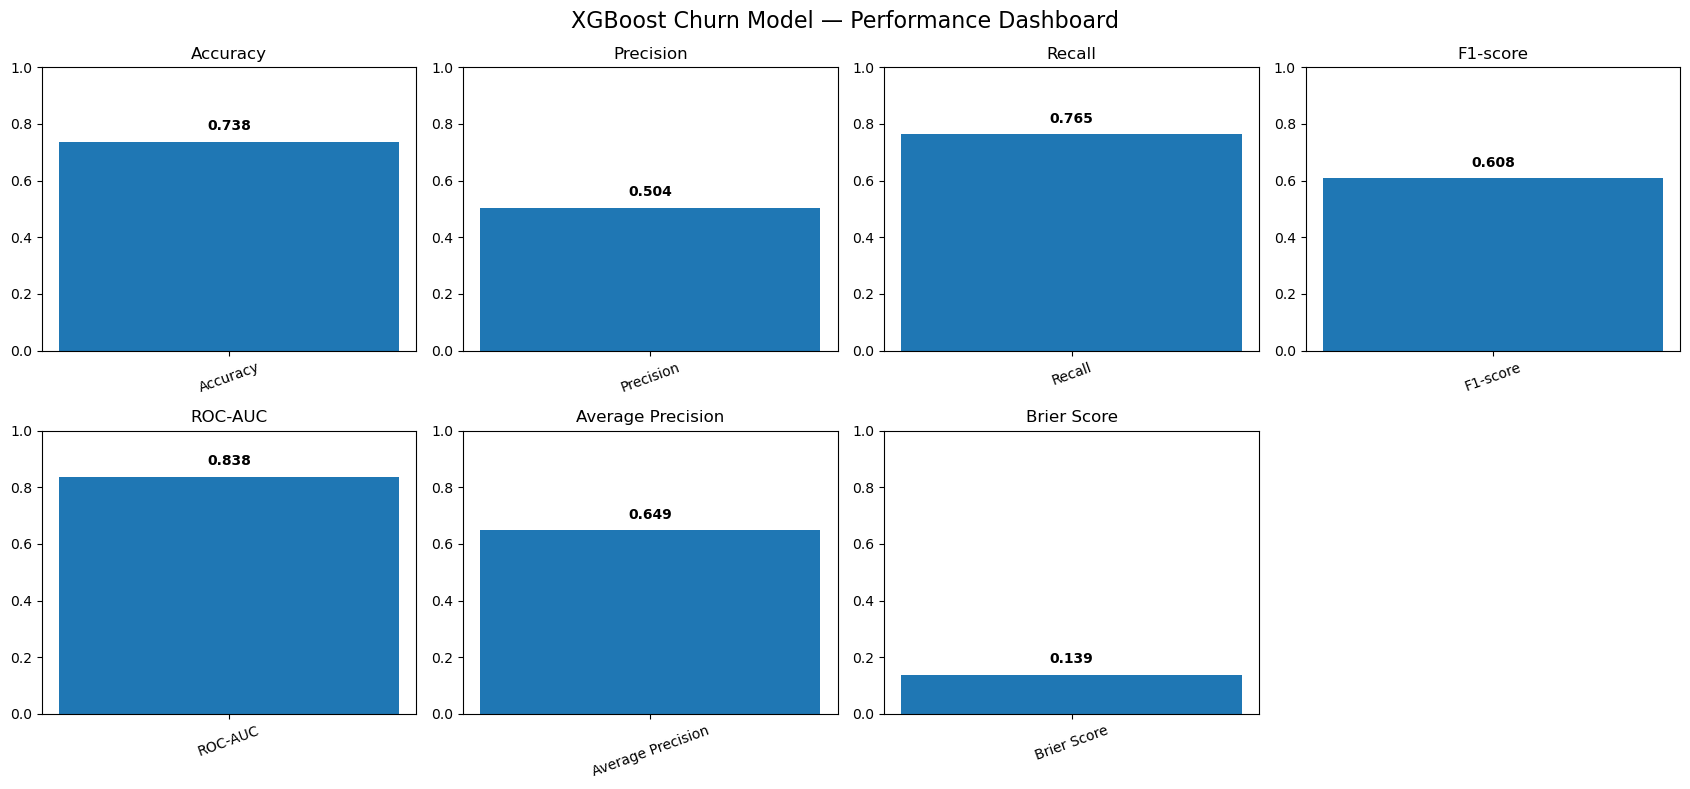

In [6]:
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob),
    "Brier Score": brier_score_loss(y_test, y_prob),
}
metrics_df = pd.DataFrame({"Metric": list(metrics), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.4f}"}))

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (name, value) in zip(axes.flat, metrics.items()):
    ax.bar([name], [value])
    ax.set_ylim(0, 1)
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=20)
    ax.text(0, min(value + 0.04, 0.96), f"{value:.3f}", ha="center", fontweight="bold")
axes.flat[-1].axis("off")
fig.suptitle("XGBoost Churn Model — Performance Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

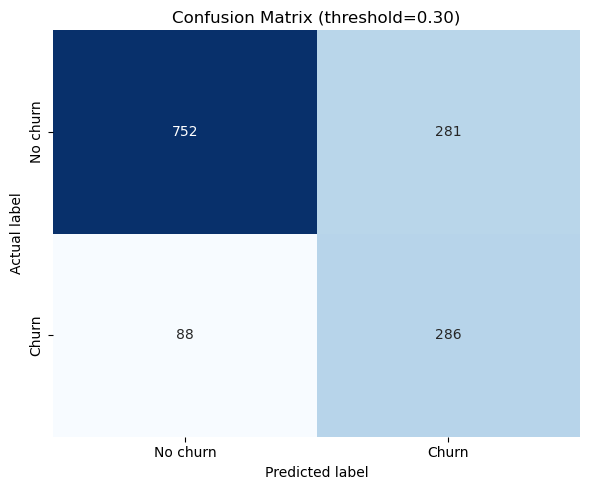

              precision    recall  f1-score   support

    No churn       0.90      0.73      0.80      1033
       Churn       0.50      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.75      1407



In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"])
plt.title(f"Confusion Matrix (threshold={DECISION_THRESHOLD:.2f})")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

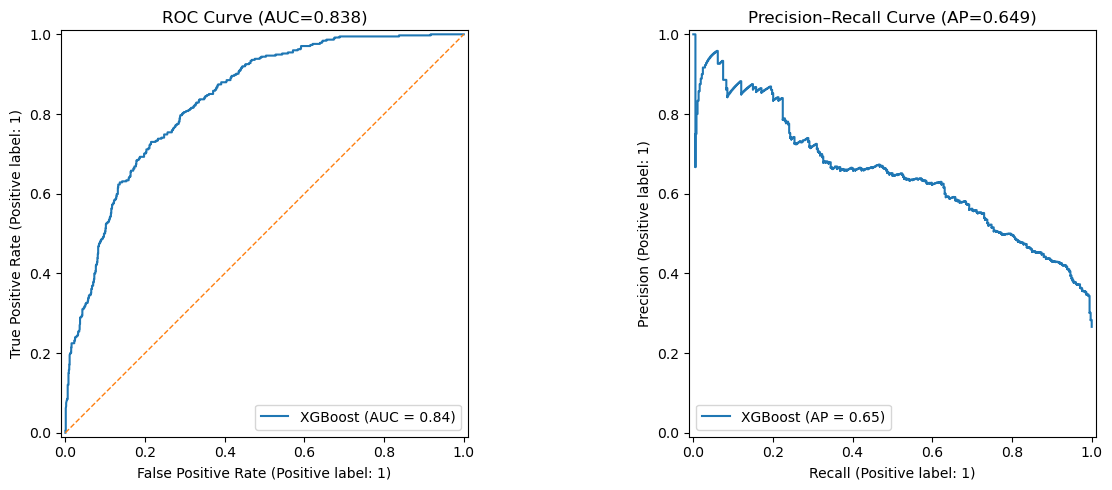

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[0], name="XGBoost")
axes[0].plot([0, 1], [0, 1], "--", linewidth=1)
axes[0].set_title(f"ROC Curve (AUC={metrics['ROC-AUC']:.3f})")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="XGBoost")
axes[1].set_title(f"Precision–Recall Curve (AP={metrics['Average Precision']:.3f})")
plt.tight_layout()
plt.show()

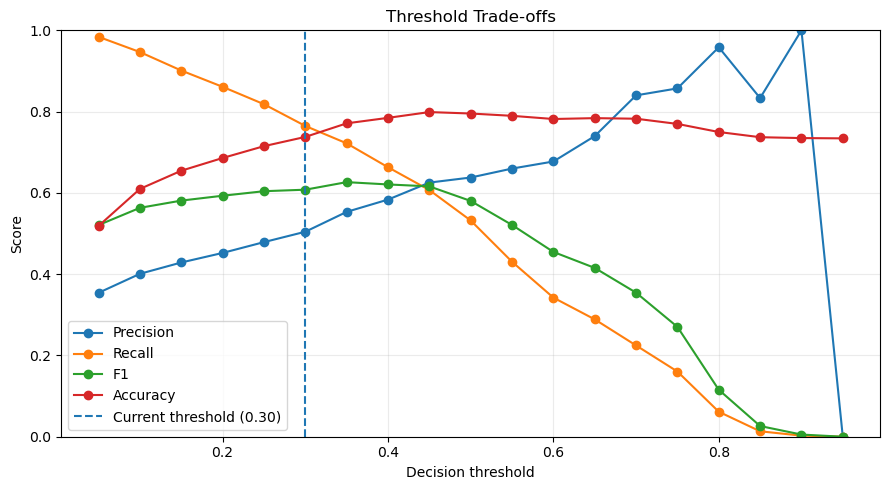

,threshold,accuracy,precision,recall,f1
0,0.050,0.519,0.354,0.984,0.521
1,0.100,0.610,0.401,0.947,0.563
2,0.150,0.655,0.429,0.901,0.581
3,0.200,0.686,0.452,0.861,0.593
4,0.250,0.715,0.479,0.818,0.604
5,0.300,0.738,0.504,0.765,0.608
6,0.350,0.771,0.553,0.722,0.626
7,0.400,0.785,0.584,0.663,0.621
8,0.450,0.799,0.625,0.607,0.616
9,0.500,0.795,0.638,0.532,0.580


In [9]:
# Descriptive threshold sweep. Do not select a final threshold using test data.
threshold_rows = []
for threshold in np.arange(0.05, 0.951, 0.05):
    pred = (y_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
threshold_df = pd.DataFrame(threshold_rows)

plt.figure(figsize=(9, 5))
for col in ["precision", "recall", "f1", "accuracy"]:
    plt.plot(threshold_df["threshold"], threshold_df[col], marker="o", label=col.title())
plt.axvline(DECISION_THRESHOLD, linestyle="--", label=f"Current threshold ({DECISION_THRESHOLD:.2f})")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Threshold Trade-offs")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()
display(threshold_df.style.format("{:.3f}"))

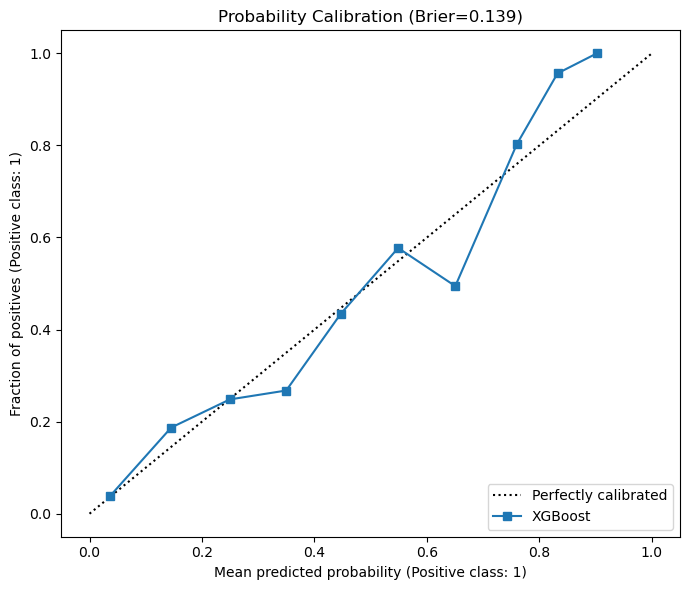

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(y_test, y_prob, n_bins=10, strategy="uniform", ax=ax, name="XGBoost")
ax.set_title(f"Probability Calibration (Brier={metrics['Brier Score']:.3f})")
plt.tight_layout()
plt.show()

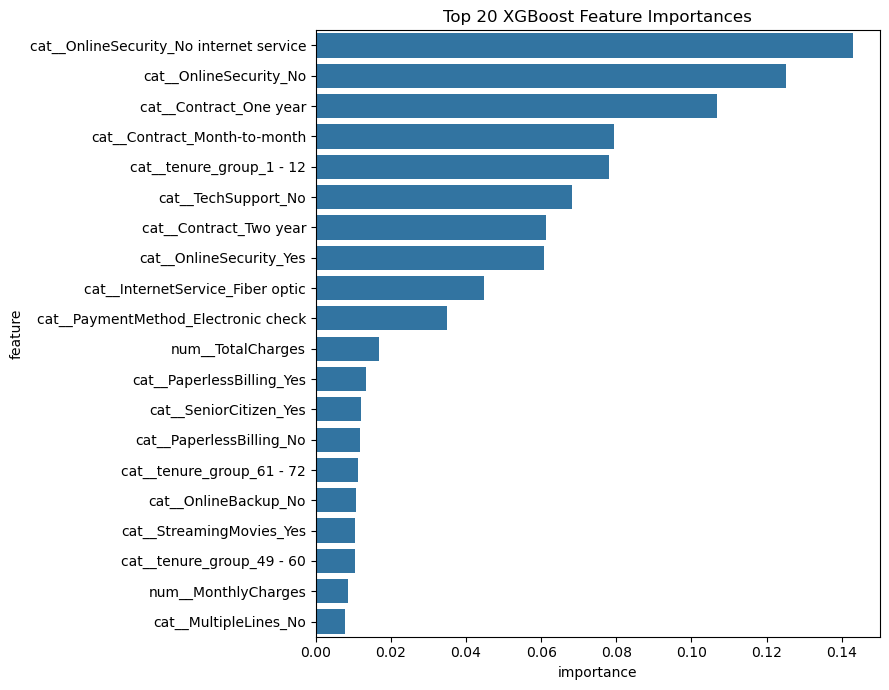

,feature,importance
19,cat__OnlineSecurity_No internet service,0.143025
18,cat__OnlineSecurity_No,0.125166
37,cat__Contract_One year,0.106917
36,cat__Contract_Month-to-month,0.079424
45,cat__tenure_group_1 - 12,0.077917
27,cat__TechSupport_No,0.068268
38,cat__Contract_Two year,0.061271
20,cat__OnlineSecurity_Yes,0.060790
16,cat__InternetService_Fiber optic,0.044823
43,cat__PaymentMethod_Electronic check,0.034816


In [11]:
# Built-in feature importance ranks transformed inputs; it does not show causal effects.
if hasattr(model, "feature_importances_"):
    try:
        feature_names = list(preprocessor.get_feature_names_out())
    except Exception:
        feature_names = [f"feature_{i}" for i in range(len(model.feature_importances_))]
    if len(feature_names) != len(model.feature_importances_):
        feature_names = [f"feature_{i}" for i in range(len(model.feature_importances_))]

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": np.asarray(model.feature_importances_)
    }).sort_values("importance", ascending=False).head(20)

    plt.figure(figsize=(9, 7))
    sns.barplot(data=importance_df, x="importance", y="feature")
    plt.title("Top 20 XGBoost Feature Importances")
    plt.tight_layout()
    plt.show()
    display(importance_df)
else:
    print("Model does not expose feature_importances_.")

In [12]:
# Export metric summaries for your project report.
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
metrics_df.to_csv(REPORT_DIR / "xgboost_test_metrics.csv", index=False)
threshold_df.to_csv(REPORT_DIR / "xgboost_threshold_analysis.csv", index=False)
print("Saved:", REPORT_DIR / "xgboost_test_metrics.csv")
print("Saved:", REPORT_DIR / "xgboost_threshold_analysis.csv")

Saved: c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\reports\xgboost_test_metrics.csv
Saved: c:\Users\ASUS\Documents\GIT_FOLDERS\ChurnIQ\reports\xgboost_threshold_analysis.csv
